In [1]:
x=1

In [18]:
import scanpy as sc
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
sc.set_figure_params(vector_friendly=True, figsize=(6,4), dpi=300)

In [19]:
adata = sc.read('/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/multigrate_mil_reg/pbmc_scvi/6e49b5e194_adata_both.h5ad')
adata

/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/sc/lib/python3.10/site-packages/anndata/__init__.py:42: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


AnnData object with n_obs × n_vars = 215678 × 30
    obs: 'sample_id', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'full_clustering', 'initial_clustering', 'Resample', 'Collection_Day', 'Sex', 'Age_interval', 'Swab_result', 'Status', 'Smoker', 'Status_on_day_collection', 'Status_on_day_collection_summary', 'Days_from_onset', 'Site', 'time_after_LPS', 'Worst_Clinical_Status', 'Outcome', 'patient_id', 'split0', 'split1', 'split2', 'split3', 'split4', '_scvi_batch', '_scvi_labels', 'group', 'cell_attn_0', 'cell_attn_1', 'cell_attn_2', 'cell_attn_3', 'cell_attn_4', 'cell_attn'
    uns: 'Age_interval_colors', 'Collection_Day_colors', 'Days_from_onset_colors', 'Outcome_colors', 'Resample_colors', 'Sex_colors', 'Site_colors', 'Smoker_colors', 'Status_colors', 'Status_on_day_collection_colors', 'Status_on_day_collection_summary_colors', 'Swab_result_colors', 'Worst_Clinical_Status_colors', 'full_clustering_colors', 'initial_clustering_colors', 'neighbors

In [20]:
celltype_col = 'initial_clustering'
celltype_counts = adata.obs[celltype_col].value_counts()
celltype_order = list(celltype_counts.index)
celltype_colors = sns.color_palette('tab20', len(celltype_order))
celltype_palette = dict(zip(celltype_order, celltype_colors))
celltype_palette

{'CD4': (0.12156862745098039, 0.4666666666666667, 0.7058823529411765),
 'CD14': (0.6823529411764706, 0.7803921568627451, 0.9098039215686274),
 'CD8': (1.0, 0.4980392156862745, 0.054901960784313725),
 'NK_16hi': (1.0, 0.7333333333333333, 0.47058823529411764),
 'B_cell': (0.17254901960784313, 0.6274509803921569, 0.17254901960784313),
 'CD16': (0.596078431372549, 0.8745098039215686, 0.5411764705882353),
 'Platelets': (0.8392156862745098, 0.15294117647058825, 0.1568627450980392),
 'gdT': (1.0, 0.596078431372549, 0.5882352941176471),
 'Treg': (0.5803921568627451, 0.403921568627451, 0.7411764705882353),
 'NK_56hi': (0.7725490196078432, 0.6901960784313725, 0.8352941176470589),
 'Plasmablast': (0.5490196078431373, 0.33725490196078434, 0.29411764705882354),
 'DCs': (0.7686274509803922, 0.611764705882353, 0.5803921568627451),
 'MAIT': (0.8901960784313725, 0.4666666666666667, 0.7607843137254902),
 'pDC': (0.9686274509803922, 0.7137254901960784, 0.8235294117647058),
 'Lymph_prolif': (0.49803921568

In [21]:
adata_paths = {
    'scVI': '/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/multigrate_mil_reg/pbmc_scvi/6e49b5e194_adata_both.h5ad',
    'scGPT': '/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/multigrate_mil_reg/pbmc_scgpt/9f082329d4_adata_both.h5ad',
}

/lustre/groups/ml01/workspace/anastasia.litinetskaya/mambaforge/envs/sc/lib/python3.10/site-packages/anndata/__init__.py:42: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/tmp/ipykernel_1540947/608420949.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tmp.loc[:, 'fold'] = f'fold_{i}'
/tmp/ipykernel_1540947/608420949.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tmp.loc[:, 'fold'] = f'fold_{i}'
/tmp/ipyk

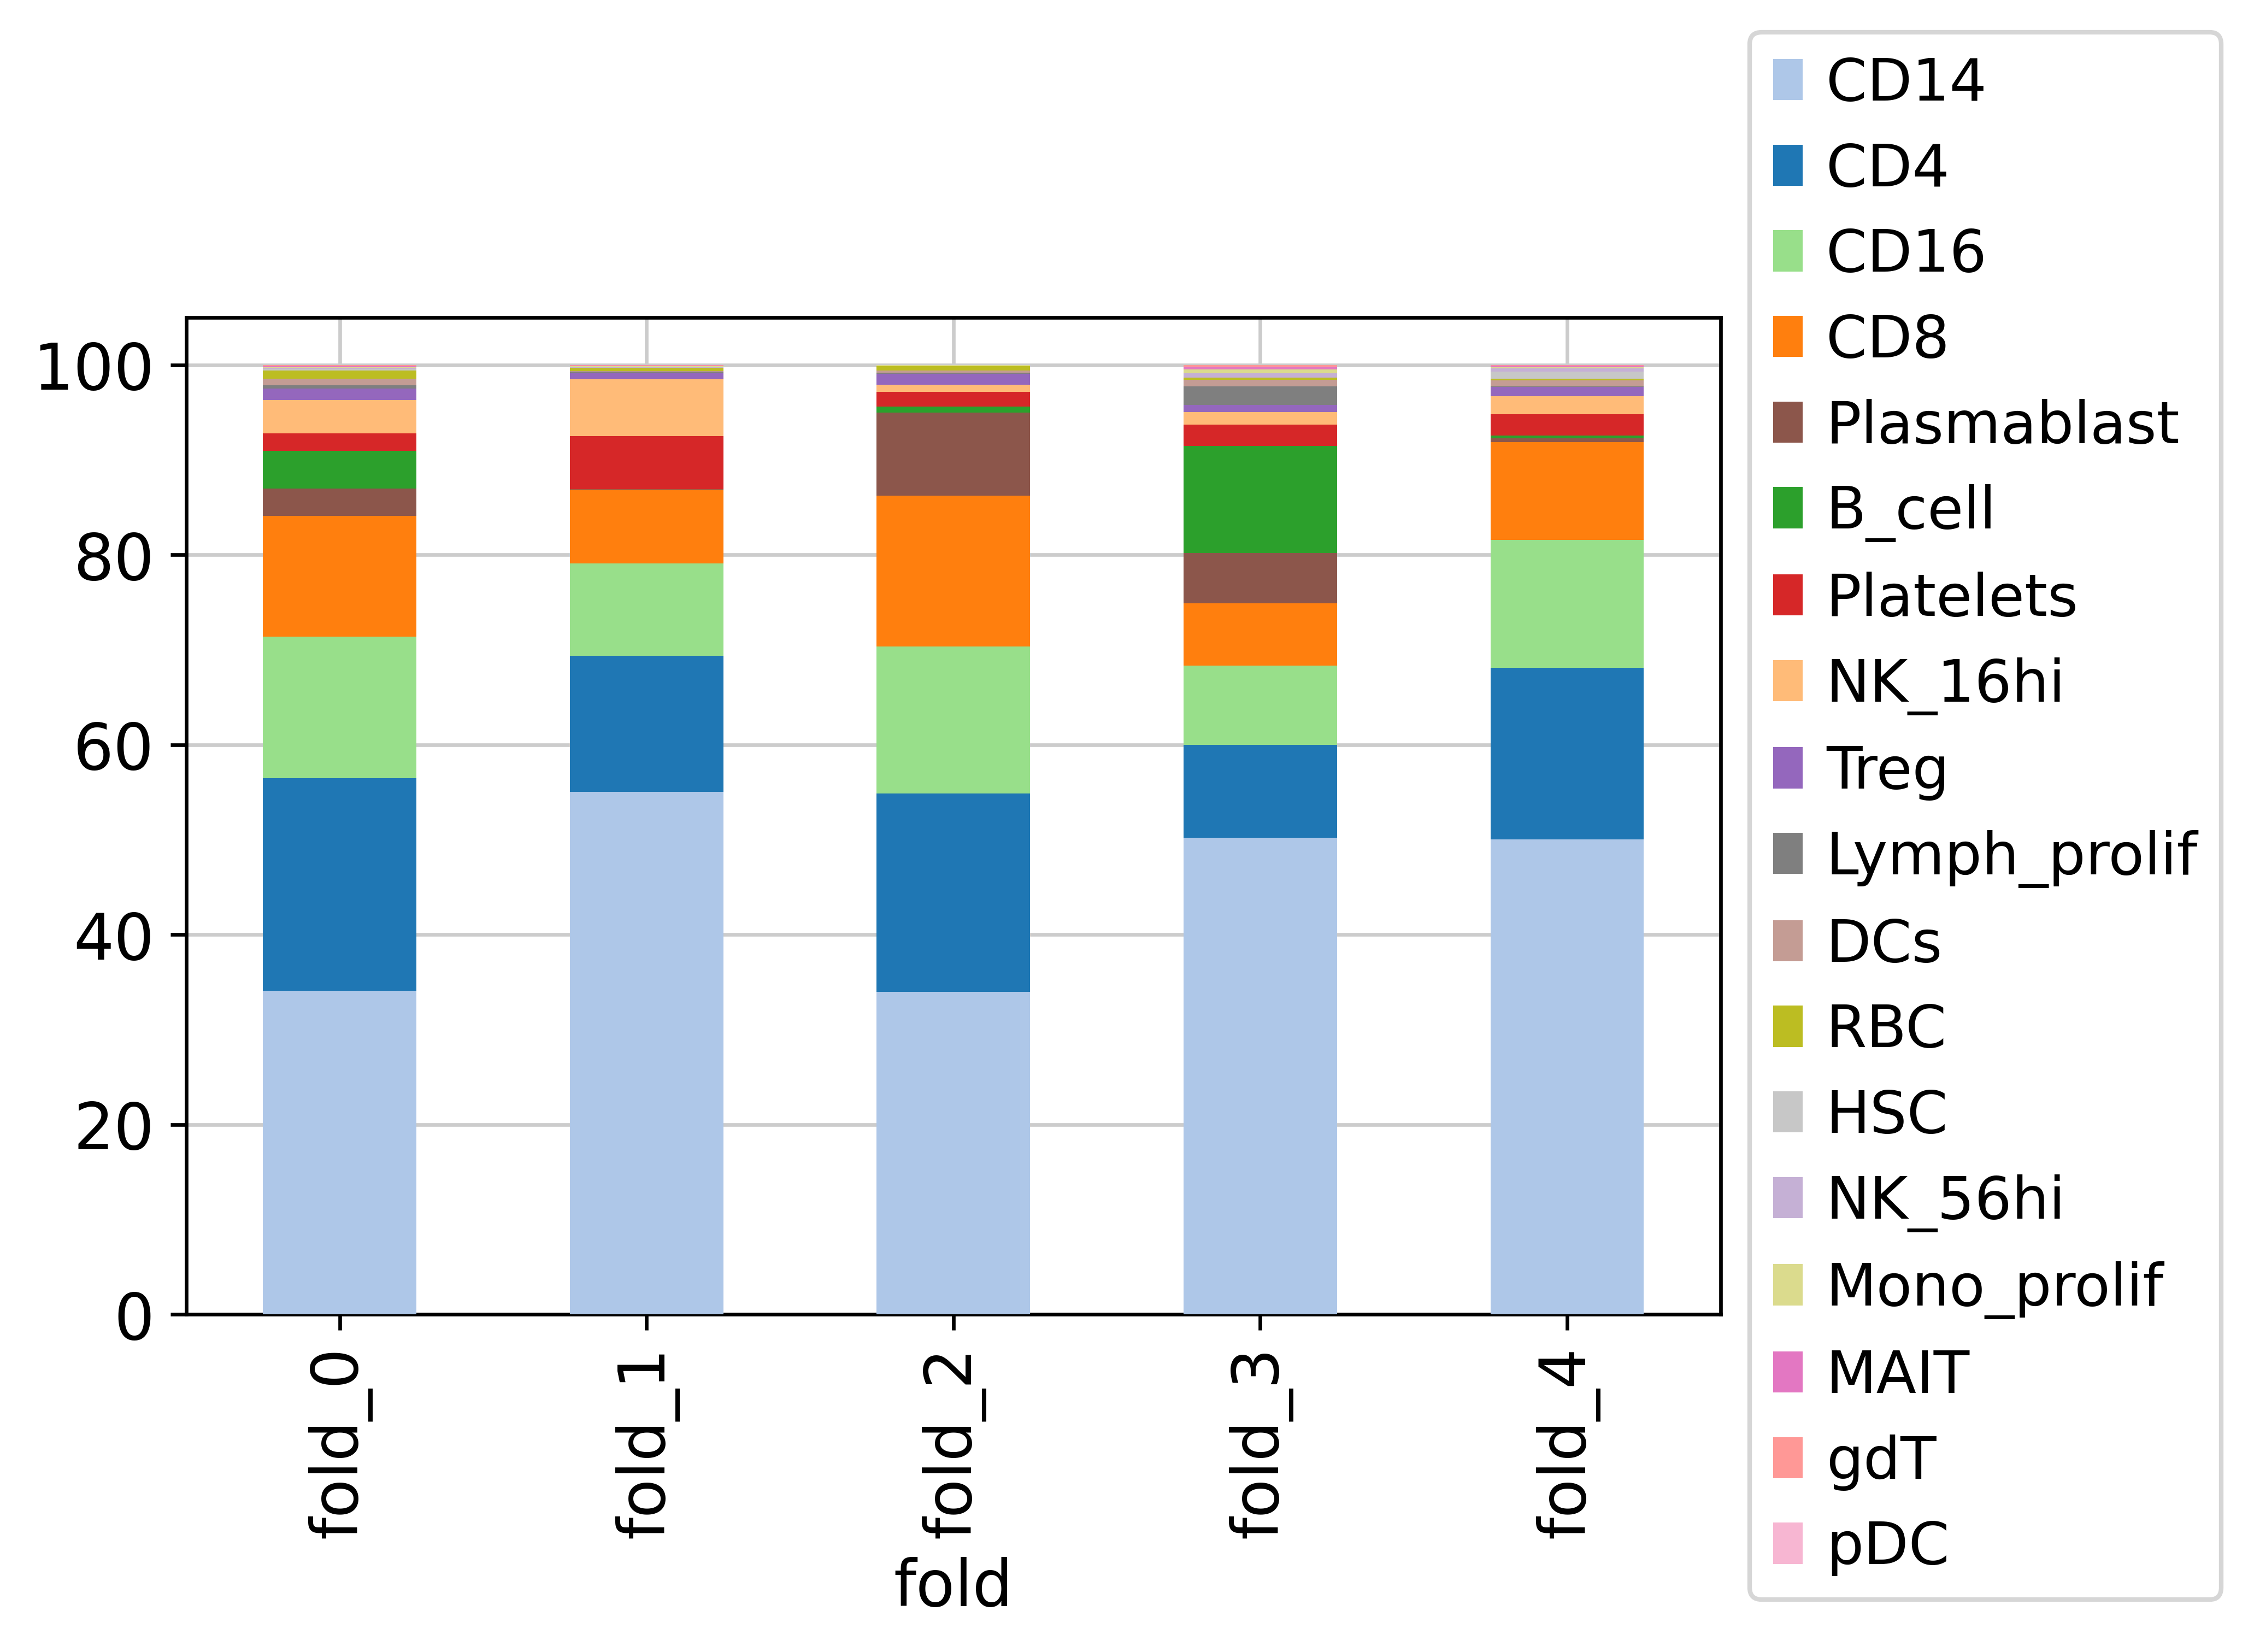

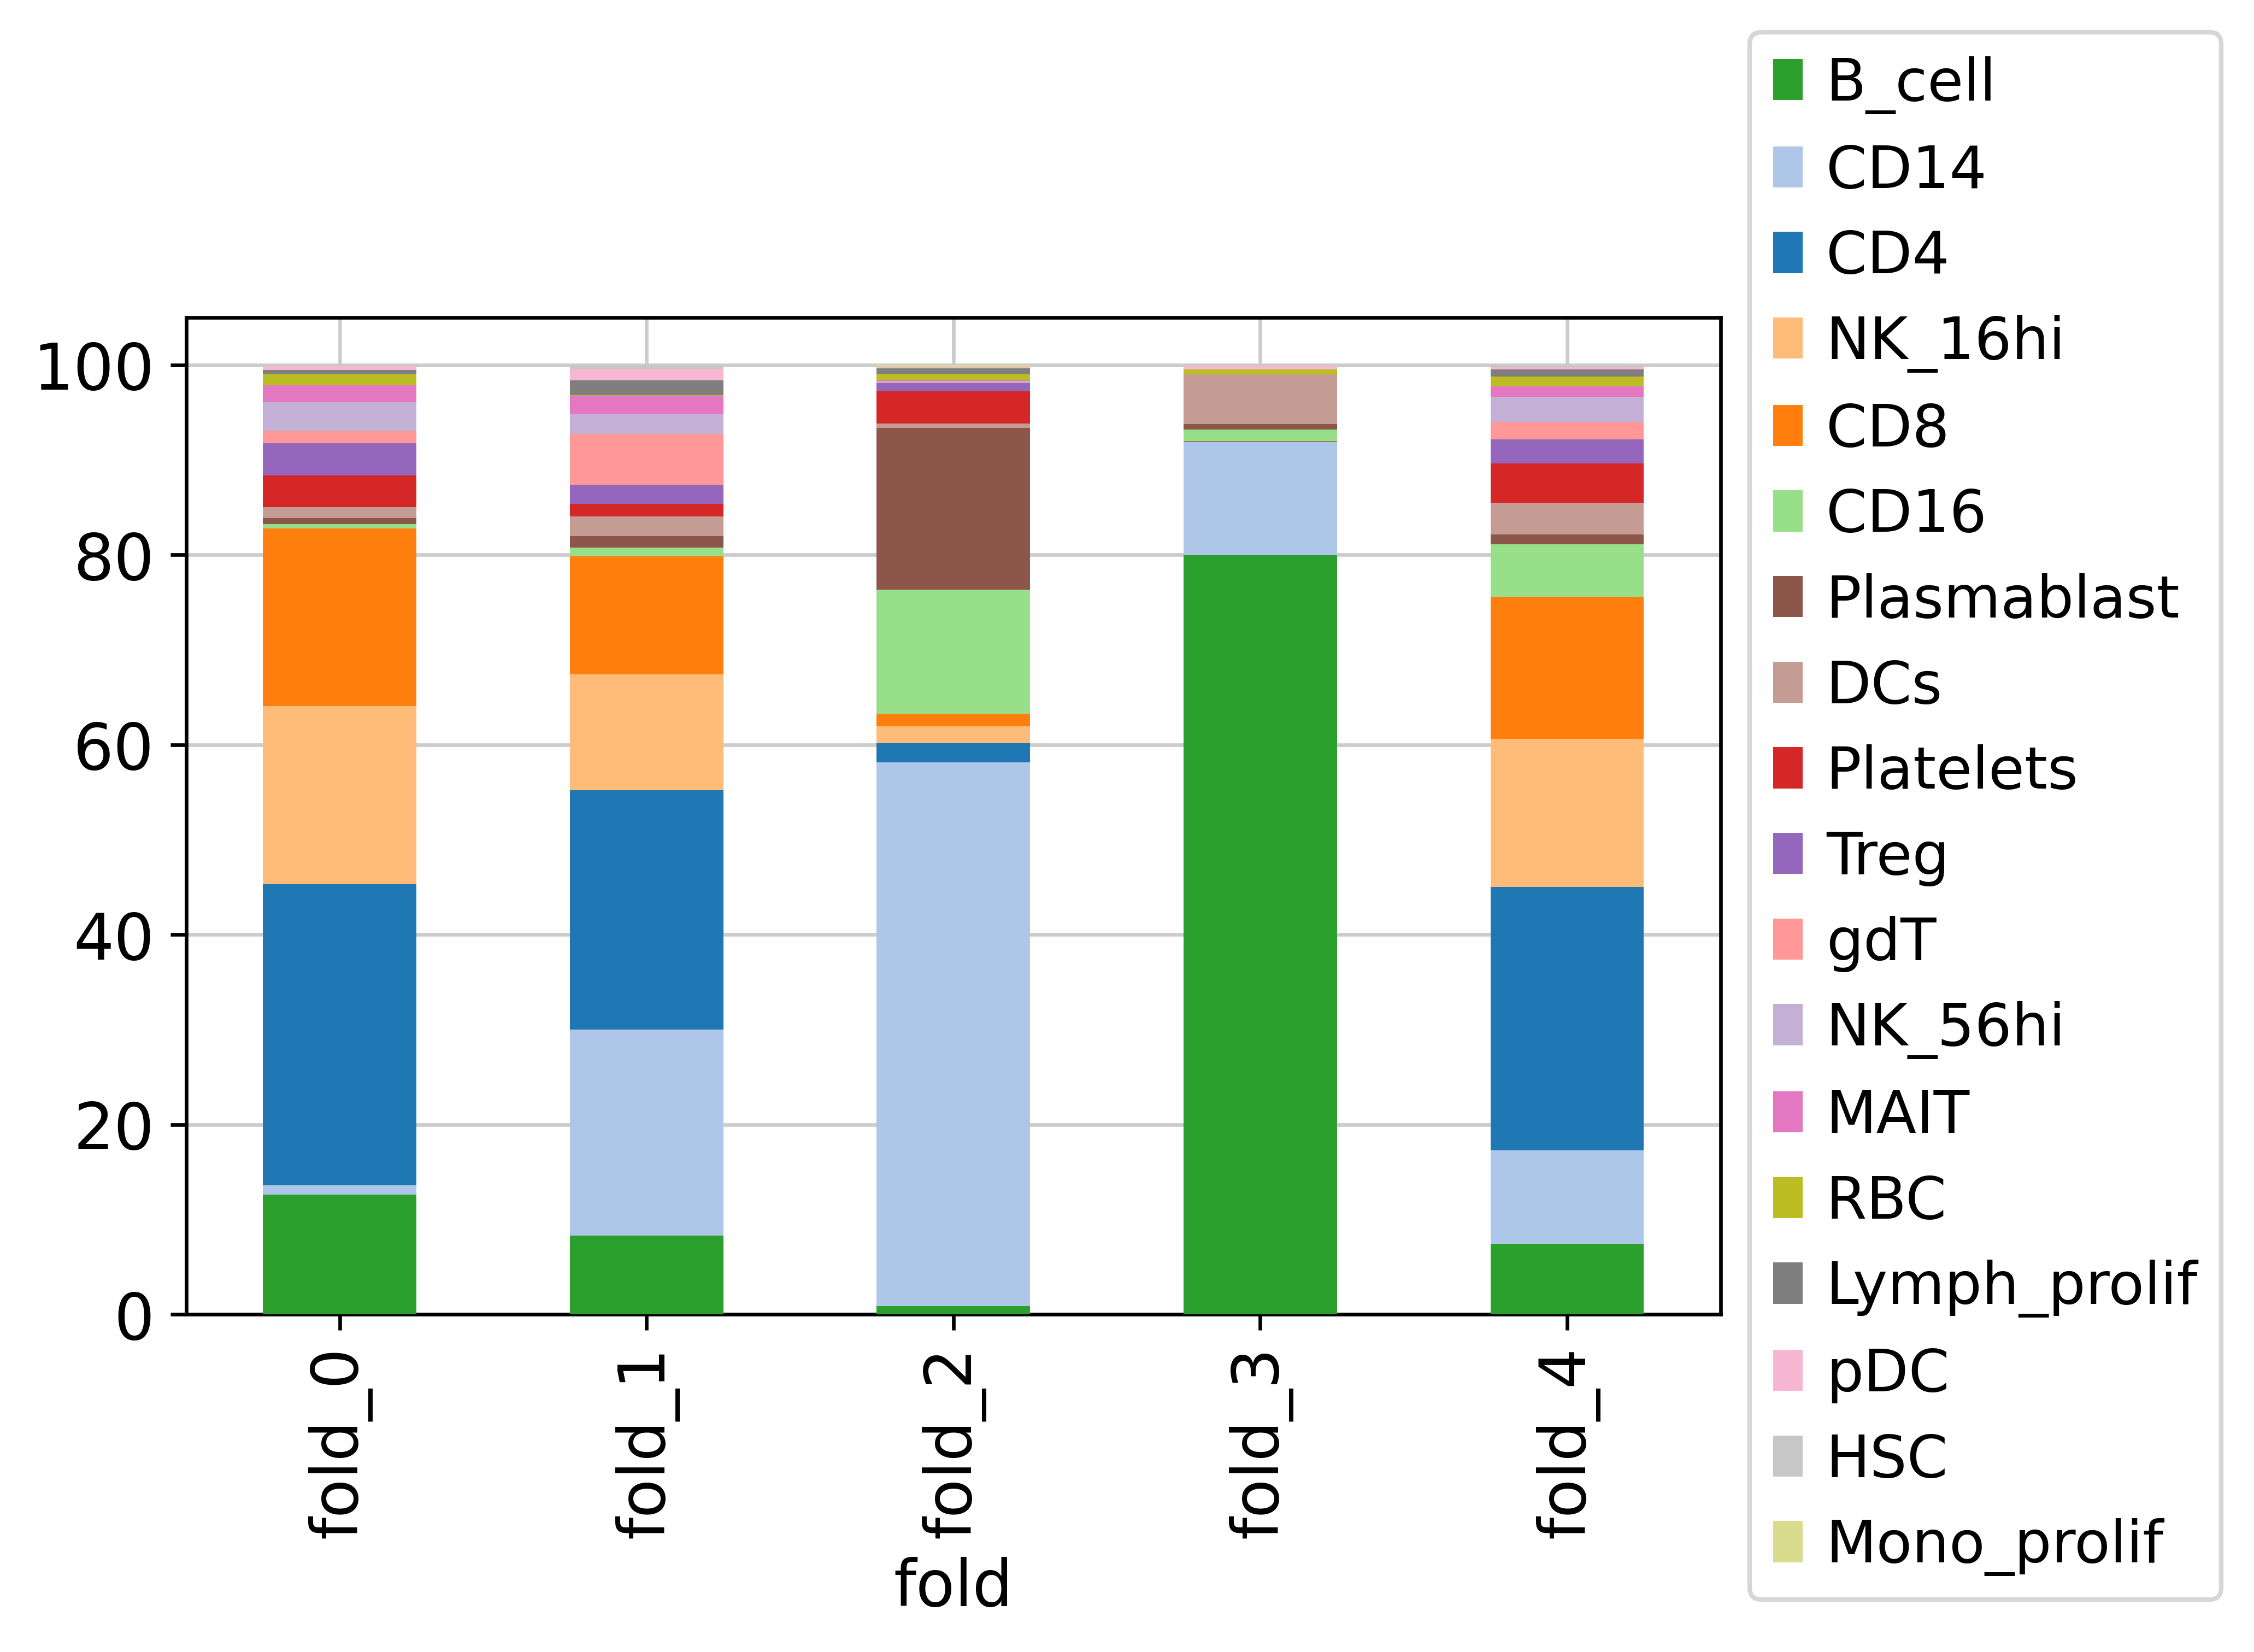

In [22]:
for method, adata_path in adata_paths.items():
    adata = sc.read(adata_path)
    for i in range(5):
        threshold_idx = int(len(adata) * 0.9)
        threshold_value = sorted(adata.obs[f'cell_attn_{i}'])[threshold_idx]
        adata.obs[f'group_{i}'] = 'all cells'
        adata.obs.loc[adata.obs[f'cell_attn_{i}'] >= threshold_value, f'group_{i}'] = 'top 10% cells'
        adata.obs[f'top_cells_{i}'] = False
        adata.obs.loc[adata[adata.obs[f'group_{i}'] == 'top 10% cells'].obs_names, f'top_cells_{i}'] = True
        adata.obs[f'top_cells_{i}'] = adata.obs[f'top_cells_{i}'].astype('category')
    dfs = []
    for i in range(5):
        df_tmp = adata[adata.obs[f'group_{i}'] == 'top 10% cells'].obs[['initial_clustering']]
        df_tmp.loc[:, 'fold'] = f'fold_{i}'
        dfs.append(df_tmp)
    df = pd.concat(dfs)
    df_sort = df['initial_clustering'].value_counts().sort_values(ascending=False)
    # remove celltypes from legend that are not present in the top cells
    celltype_palette_method = {ct: celltype_palette[ct] for ct in df_sort.index if ct in celltype_palette}
    df_group = df.groupby('fold').value_counts(normalize=True).mul(100)

    ax = df_group.unstack()[list(df_sort.index)].plot.bar(
        stacked=True, 
        color=celltype_palette, 
        zorder=3 
    )

    ax.grid(True, zorder=0) 
    ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

    plt.savefig(f'figures/attn_robustness_across_folds_{method}.svg', bbox_inches='tight')